In [ ]:
import random
import time
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque

In [ ]:
#define tileworld
GRID_SIZE = 15

MOVES = {
    "UP": (-1, 0),
    "DOWN": (1, 0),
    "LEFT": (0, -1),
    "RIGHT": (0, 1)
}

In [ ]:
#create the world
class TileWorld:
    def __init__(self, size=15, seed=0,
                 hole_probability=0.05,
                 min_lifetime=10,
                 max_lifetime=30):

        self.size = size
        self.rng = random.Random(seed)

        self.hole_probability = hole_probability
        self.min_lifetime = min_lifetime
        self.max_lifetime = max_lifetime

        self.holes = {}
        self.tick = 0

        self.total_holes_appeared = 0
        self.total_holes_filled = 0

        self.event_log = []

    def valid_cell(self, cell):
        r, c = cell
        return 0 <= r < self.size and 0 <= c < self.size

    def add_hole(self, cell=None):

        if cell is None:
            available = [
                (r, c)
                for r in range(self.size)
                for c in range(self.size)
                if (r, c) not in self.holes
            ]

            if not available:
                return None

            cell = self.rng.choice(available)

        lifetime = self.rng.randint(
            self.min_lifetime,
            self.max_lifetime
        )

        self.holes[cell] = lifetime
        self.total_holes_appeared += 1

        self.event_log.append(
            f"Tick {self.tick}: HOLE APPEARED at {cell}"
        )

        return cell

    def advance(self, ticks=1):

        for _ in range(ticks):

            self.tick += 1

            # Existing holes lose one unit of lifetime
            expired = []

            for cell in list(self.holes.keys()):
                self.holes[cell] -= 1

                if self.holes[cell] <= 0:
                    expired.append(cell)

            # Remove expired holes
            for cell in expired:
                del self.holes[cell]

                self.event_log.append(
                    f"Tick {self.tick}: HOLE EXPIRED at {cell}"
                )

            # Randomly generate a new hole
            if self.rng.random() < self.hole_probability:
                self.add_hole()

    def fill_hole(self, cell):

        if cell in self.holes:

            del self.holes[cell]

            self.total_holes_filled += 1

            self.event_log.append(
                f"Tick {self.tick}: HOLE FILLED at {cell}"
            )

            return True

        return False

    def percept(self, agent_position):

        return {
            "position": agent_position,
            "holes": dict(self.holes),
            "tick": self.tick
        }

In [ ]:
#test the world
world = TileWorld(seed=42)

print("Grid size:", world.size)
print("Initial holes:", world.holes)

Grid size: 15
Initial holes: {}


In [ ]:
#manually create a hole
world.add_hole((5, 5))

print("Holes:", world.holes)

Holes: {(5, 5): 30}


In [ ]:
#visualize the world
def display_world(world, agent_position, intention=None):

    grid = np.zeros((world.size, world.size))

    for hole in world.holes:
        r, c = hole
        grid[r, c] = 1

    ar, ac = agent_position
    grid[ar, ac] = 2

    plt.figure(figsize=(7, 7))
    plt.imshow(grid)

    plt.xticks(range(world.size))
    plt.yticks(range(world.size))
    plt.grid()

    plt.title(
        f"Tileworld | Tick={world.tick} | "
        f"Intention={intention}"
    )

    plt.show()

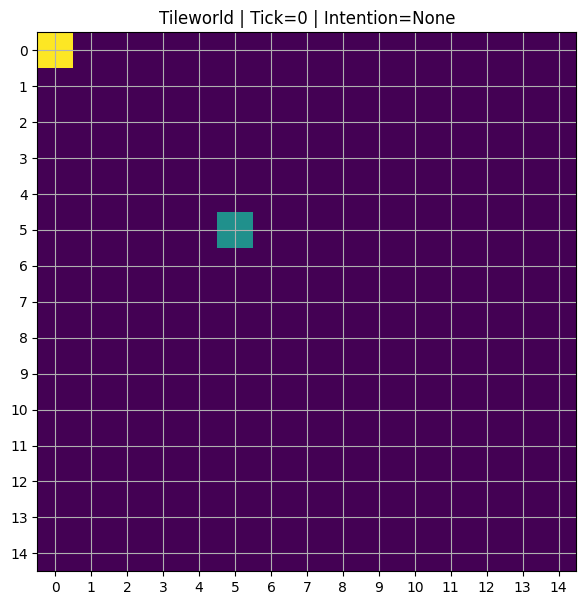

In [ ]:
display_world(world, (0,0))

In [ ]:
#create the BDI agent
class BDIAgent:

    def __init__(self, world, start=(0, 0), gamma=1):

        self.world = world

        self.position = start

        # B = Beliefs
        self.beliefs = {}

        # I = Intention
        self.intention = None

        # π = Plan
        self.plan_actions = []

        # Reconsideration interval
        self.gamma = gamma

        # Number of actions since last reconsideration
        self.since_reconsideration = 0

        # Statistics
        self.actions_taken = 0
        self.deliberations = 0
        self.holes_filled = 0

        # Event trace
        self.trace = []

In [ ]:
#Belief Revision
def brf(self, percept):

    self.beliefs = {
        "position": percept["position"],
        "holes": dict(percept["holes"]),
        "tick": percept["tick"]
    }

    return self.beliefs


BDIAgent.brf = brf

In [ ]:
#options function
def options(self):

    holes = self.beliefs.get("holes", {})

    return list(holes.keys())


BDIAgent.options = options

In [ ]:
#shortest path planner
def shortest_path(self, start, goal):

    if start == goal:
        return []

    queue = deque()

    queue.append(start)

    parent = {
        start: None
    }

    move_used = {}

    while queue:

        current = queue.popleft()

        for action, (dr, dc) in MOVES.items():

            nr = current[0] + dr
            nc = current[1] + dc

            next_cell = (nr, nc)

            if not self.world.valid_cell(next_cell):
                continue

            if next_cell in parent:
                continue

            parent[next_cell] = current

            move_used[next_cell] = action

            if next_cell == goal:

                path = []

                node = goal

                while parent[node] is not None:

                    path.append(
                        move_used[node]
                    )

                    node = parent[node]

                path.reverse()

                return path

            queue.append(next_cell)

    return None


BDIAgent.shortest_path = shortest_path

In [ ]:
#filter / deliberation
def filter(self, options):

    if not options:
        return None

    best_option = None

    best_distance = float("inf")

    for hole in options:

        path = self.shortest_path(
            self.position,
            hole
        )

        if path is not None:

            distance = len(path)

            if distance < best_distance:

                best_distance = distance

                best_option = hole

    return best_option


BDIAgent.filter = filter

In [ ]:
#plan function
def make_plan(self):

    if self.intention is None:
        return []

    path = self.shortest_path(
        self.position,
        self.intention
    )

    if path is None:
        return []

    return path


BDIAgent.make_plan = make_plan

In [ ]:
#execute an action
def execute_action(self, action):

    dr, dc = MOVES[action]

    new_position = (
        self.position[0] + dr,
        self.position[1] + dc
    )

    if self.world.valid_cell(new_position):

        self.position = new_position

        self.actions_taken += 1

        return True

    return False


BDIAgent.execute_action = execute_action

In [ ]:
#check whether intention was archieved
def check_achievement(self):

    if self.intention is None:
        return False

    if self.position == self.intention:

        target = self.intention

        if self.world.fill_hole(target):

            self.holes_filled += 1

            self.trace.append(
                f"Tick {self.world.tick}: "
                f"ACHIEVED {target}"
            )

        else:

            self.trace.append(
                f"Tick {self.world.tick}: "
                f"INTENTION {target} "
                f"NO LONGER EXISTS"
            )

        self.intention = None

        self.plan_actions = []

        return True

    return False


BDIAgent.check_achievement = check_achievement

In [ ]:
#single-minded reconsideration
def reconsider(self):

    self.deliberations += 1

    options_list = self.options()

    # -----------------------------------------
    # No options available
    # -----------------------------------------

    if not options_list:

        self.intention = None

        self.plan_actions = []

        self.since_reconsideration = 0

        return

    # -----------------------------------------
    # Check current intention
    # -----------------------------------------

    if self.intention is not None:

        if self.intention not in self.beliefs["holes"]:

            old_intention = self.intention

            self.trace.append(
                f"Tick {self.world.tick}: "
                f"DROPPED {old_intention} "
                f"(unachievable)"
            )

            self.intention = None

            self.plan_actions = []

    # -----------------------------------------
    # Select new intention
    # -----------------------------------------

    new_intention = self.filter(options_list)

    if new_intention is None:

        self.intention = None

        self.plan_actions = []

    elif new_intention != self.intention:

        old_intention = self.intention

        self.intention = new_intention

        self.plan_actions = self.make_plan()

        if old_intention is None:

            self.trace.append(
                f"Tick {self.world.tick}: "
                f"COMMIT {new_intention}"
            )

        else:

            self.trace.append(
                f"Tick {self.world.tick}: "
                f"SWITCH {old_intention} "
                f"-> {new_intention}"
            )

    self.since_reconsideration = 0


BDIAgent.reconsider = reconsider

In [ ]:
#main BDI cycle
def step(self, world_speed=1):

    # -----------------------------------------
    # 1. PERCEIVE
    # -----------------------------------------

    percept = self.world.percept(
        self.position
    )

    # -----------------------------------------
    # 2. BELIEF REVISION
    # -----------------------------------------

    self.brf(percept)

    # -----------------------------------------
    # 3. INITIAL DELIBERATION
    # -----------------------------------------

    if self.intention is None:

        options_list = self.options()

        if options_list:

            self.intention = self.filter(
                options_list
            )

            if self.intention is not None:

                self.plan_actions = self.make_plan()

                self.trace.append(
                    f"Tick {self.world.tick}: "
                    f"COMMIT {self.intention}"
                )

                self.deliberations += 1

    # -----------------------------------------
    # 4. EXECUTE ACTION
    # -----------------------------------------

    if self.plan_actions:

        action = self.plan_actions.pop(0)

        self.execute_action(action)

        self.since_reconsideration += 1

        # World changes while agent acts
        self.world.advance(world_speed)

    else:

        self.world.advance(world_speed)

    # -----------------------------------------
    # 5. CHECK ACHIEVEMENT
    # -----------------------------------------

    self.check_achievement()

    # -----------------------------------------
    # 6. RECONSIDERATION
    # -----------------------------------------

    if self.since_reconsideration >= self.gamma:

        self.reconsider()


BDIAgent.step = step

In [ ]:
#effectiveness
def effectiveness(self):

    if self.world.total_holes_appeared == 0:

        return 0.0

    return (
        self.world.total_holes_filled
        / self.world.total_holes_appeared
    )


BDIAgent.effectiveness = effectiveness

In [ ]:
#run one complete simulation
def run_simulation(
    seed=42,
    gamma=1,
    world_speed=1,
    steps=100
):

    world = TileWorld(
        size=15,
        seed=seed,
        hole_probability=0.08,
        min_lifetime=10,
        max_lifetime=30
    )

    agent = BDIAgent(
        world=world,
        start=(0, 0),
        gamma=gamma
    )

    for _ in range(steps):

        agent.step(world_speed=world_speed)

    return world, agent

In [ ]:
world, agent = run_simulation(
    seed=42,
    gamma=1,
    world_speed=1,
    steps=100
)

print("Holes appeared :", world.total_holes_appeared)
print("Holes filled   :", world.total_holes_filled)
print("Effectiveness  :", agent.effectiveness())
print("Actions taken  :", agent.actions_taken)
print("Deliberations  :", agent.deliberations)

Holes appeared : 10
Holes filled   : 6
Effectiveness  : 0.6
Actions taken  : 70
Deliberations  : 78


In [ ]:
#view the event trace
for event in agent.trace:
    print(event)

Tick 2: COMMIT (4, 10)
Tick 12: SWITCH (4, 10) -> (3, 5)
Tick 14: ACHIEVED (3, 5)
Tick 14: COMMIT (3, 5)
Tick 15: INTENTION (3, 5) NO LONGER EXISTS
Tick 15: COMMIT (3, 10)
Tick 20: ACHIEVED (3, 10)
Tick 20: COMMIT (3, 10)
Tick 21: INTENTION (3, 10) NO LONGER EXISTS
Tick 28: COMMIT (7, 12)
Tick 34: ACHIEVED (7, 12)
Tick 34: COMMIT (7, 12)
Tick 35: INTENTION (7, 12) NO LONGER EXISTS
Tick 35: COMMIT (5, 0)
Tick 37: SWITCH (5, 0) -> (3, 13)
Tick 40: ACHIEVED (3, 13)
Tick 40: COMMIT (3, 13)
Tick 41: INTENTION (3, 13) NO LONGER EXISTS
Tick 41: COMMIT (5, 0)
Tick 56: ACHIEVED (5, 0)
Tick 56: COMMIT (5, 0)
Tick 57: INTENTION (5, 0) NO LONGER EXISTS
Tick 57: COMMIT (10, 13)
Tick 59: SWITCH (10, 13) -> (14, 1)
Tick 67: ACHIEVED (14, 1)
Tick 67: COMMIT (14, 1)
Tick 68: INTENTION (14, 1) NO LONGER EXISTS
Tick 68: COMMIT (9, 10)
Tick 82: INTENTION (9, 10) NO LONGER EXISTS
Tick 97: COMMIT (12, 4)


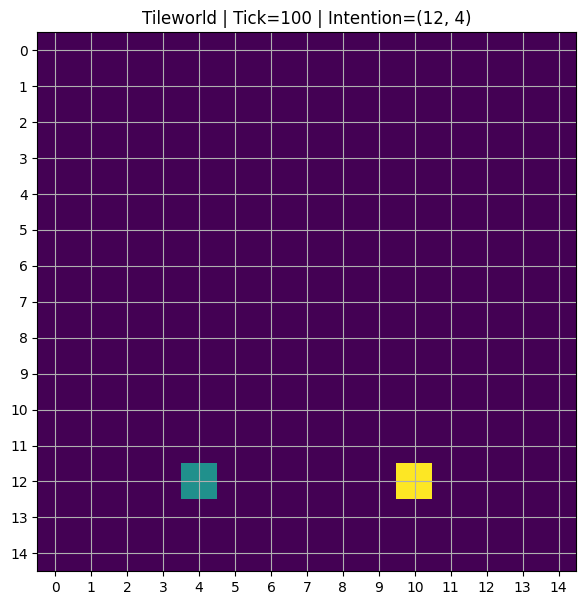

In [ ]:
#display final world
display_world(
    world,
    agent.position,
    agent.intention
)